In [1]:
import numpy as np

In [2]:
def calc_bin_tree_prices(C, up_step, step, K, rate=0.00, T=1):
    dt = T / step

    growth = np.exp(rate * dt)
    discount = np.exp(-rate * dt)

    mult_up = growth + up_step
    mult_down = growth - up_step

    # === prices ===
    end_prices = np.array([mult_up**(i) * mult_down**(step-i) for i in range(step+1)])
    end_prices = np.maximum(end_prices-K,0) 
    for _ in range(step):
        #print(end_prices)
        end_prices = discount*0.5*(end_prices[1:] + end_prices[:-1])
    return end_prices[0]

In [3]:
calc_bin_tree_prices(1.0, 0.2, 2, 1.0)

np.float64(0.10999999999999999)

## Calibration function

### First method:
one can find it easily with binary search method

In [4]:
def calibrate(price, C, step, K, rate=0.00, T=1):
    if (price < 1e-8) or (price>calc_bin_tree_prices(C, 2.0, step, K, rate=rate, T=T)):
        print("Price is not valid", calc_bin_tree_prices(C, 2.0, step, K, rate=rate, T=T))
        return

    up_step = 0.1
    max_interval = [1e-8, 2.0]
    act_interval = max_interval
    for _ in range(200): # We will terminate anyway
        act_price = calc_bin_tree_prices(C, up_step, step, K, rate=rate, T=T)
        #print(act_price, rate, act_interval)
        if np.isclose(price, act_price):
            break

        if act_price > price:
            act_interval = (act_interval[0], up_step)
        else:
            act_interval = (up_step, act_interval[1])
        up_step = np.mean(act_interval)
    return up_step

In [5]:
up_step = calibrate(0.2, 1.0, 10, 1.0)
print("Calibrated price:", calc_bin_tree_prices(1.0, up_step, 10, 1.0), "at up step:", 1+up_step)

Calibrated price: 0.2000005621040717 at up step: 1.155906867980957


## Second method: scipy.optimize

In [6]:
from scipy.optimize import minimize

In [7]:
def get_target_func(price, C, step, K):
    def f(rate):
        return np.abs(calc_bin_tree_prices(price, C, step, K)-price)
    return f

In [8]:
C = 1
price = 0.2
step=10
K = 1

res = minimize(get_target_func(price, C, step, K), up_step, method='Nelder-Mead', tol=1e-6)
up_step = res.x
print("Calibrated price:", calc_bin_tree_prices(C, up_step, step, K), "at up step:", 1+up_step)

Calibrated price: [0.20000056] at up step: [1.15590687]


## Plots

### Change K

In [9]:
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'K-rate figure')

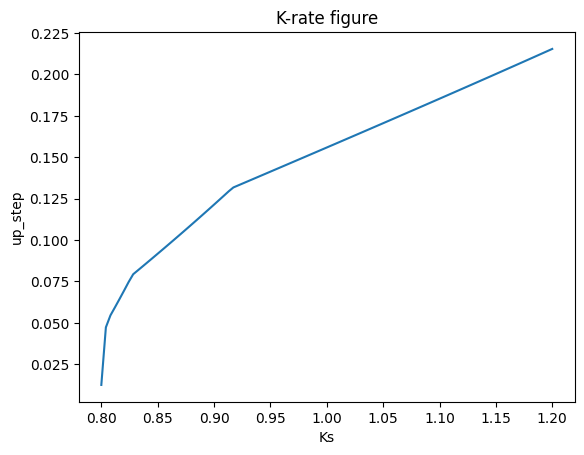

In [10]:
C = 1
price = 0.2
step=10
Ks = np.linspace(0.8, 1.2, 100)

up_steps = [calibrate(price, C, step, k) for k in Ks]


plt.plot(Ks, up_steps)
plt.xlabel("Ks")
plt.ylabel("up_step")
plt.title("K-rate figure")

## Change step size

Text(0.5, 1.0, 'K-rate figure')

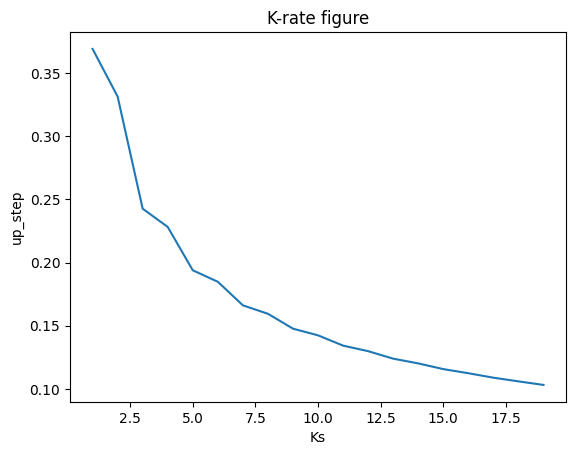

In [11]:
C = 1
price = 0.2
steps=np.arange(1, 20)
K = 1.0

# Interest rate change properly in calc_bin_tree_prices
up_steps = [calibrate(price, C, step, K, rate=0.05) for step in steps]

plt.plot(steps, up_steps)
plt.xlabel("Ks")
plt.ylabel("up_step")
plt.title("K-rate figure")

## One step plots

Text(0, 0.5, 'up_step')

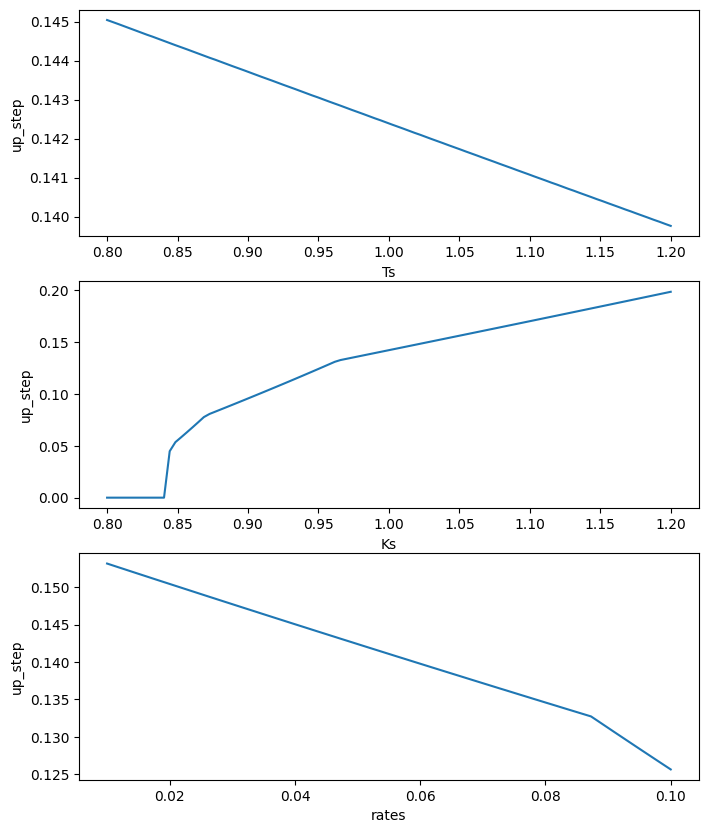

In [12]:
C = 1
price = 0.2
steps=1
K = 1.0

fig, axes = plt.subplots(3, 1, figsize=(8, 10))

Ts = np.linspace(0.8, 1.2, 100)
T_up_steps = [calibrate(price, C, step, K, rate=0.05, T=t) for t in Ts]
axes[0].plot(Ts, T_up_steps)
axes[0].set_xlabel("Ts")

Ks = np.linspace(0.8, 1.2, 100)
K_up_steps = [calibrate(price, C, step, k, rate=0.05) for k in Ks]
axes[1].plot(Ks, K_up_steps)
axes[1].set_xlabel("Ks")

rates = np.linspace(0.01, 0.1, 100)
rates_up_steps = [calibrate(price, C, step, K, rate=r) for r in rates]
axes[2].plot(rates, rates_up_steps)
axes[2].set_xlabel("rates")

axes[0].set_ylabel("up_step")
axes[1].set_ylabel("up_step")
axes[2].set_ylabel("up_step")